# Modelo de Propension de Compra - Ferreycorp

# Librerias

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                              precision_recall_curve, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

In [2]:
random_seed = 42
np.random.seed(random_seed)

In [3]:
sns.set_context("paper")
sns.set_style("whitegrid")
sns.set_palette("Set2")

# Data Loading
*Lectura y exploracion*

In [4]:
df = pd.read_csv("Dataset/compras_data.csv")
df.shape

(58693, 24)

In [5]:
df.head()

,id,dia_visita,incidencia_compra,id_marca,cantidad,ultima_marca_comprada,ultima_cantidad_comprada,precio_marca_1,precio_marca_2,precio_marca_3,...,promo_marca_3,promo_marca_4,promo_marca_5,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion,tamanio_ciudad
0,200000001,1,0,0,0,0,0,1.59,1.87,2.01,...,0,0,0,0,0,47,1,110866,1,0
1,200000001,11,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0
2,200000001,12,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0
3,200000001,16,0,0,0,0,0,1.52,1.89,1.98,...,0,0,0,0,0,47,1,110866,1,0
4,200000001,18,0,0,0,0,0,1.52,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0


In [6]:
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
id,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08,2.000000e+08
dia_visita,1.000000e+00,1.100000e+01,1.200000e+01,1.600000e+01,1.800000e+01,2.300000e+01,2.800000e+01,3.700000e+01,4.100000e+01,4.300000e+01
incidencia_compra,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
id_marca,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
cantidad,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
ultima_marca_comprada,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00
ultima_cantidad_comprada,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
precio_marca_1,1.590000e+00,1.510000e+00,1.510000e+00,1.520000e+00,1.520000e+00,1.500000e+00,1.500000e+00,1.500000e+00,1.350000e+00,1.350000e+00
precio_marca_2,1.870000e+00,1.890000e+00,1.890000e+00,1.890000e+00,1.890000e+00,1.900000e+00,1.900000e+00,1.900000e+00,1.580000e+00,1.580000e+00
precio_marca_3,2.010000e+00,1.990000e+00,1.990000e+00,1.980000e+00,1.990000e+00,1.990000e+00,1.990000e+00,1.990000e+00,1.970000e+00,1.970000e+00


# Data Preparation
*Limpieza y tipado*

El diccionario de datos indica no considerar `tamanio_ciudad`. Tambien ordenamos por cliente y dia de visita: estos datos son un panel longitudinal (varias visitas por cliente en el tiempo), no filas independientes, y eso condiciona todo lo que sigue (features historicas, split de train/test, validacion cruzada).

In [7]:
df = df.drop(columns=["tamanio_ciudad"])
df = df.sort_values(["id", "dia_visita"]).reset_index(drop=True)
df.duplicated().sum()

np.int64(0)

In [8]:
df.isna().sum()

id                          0
dia_visita                  0
incidencia_compra           0
id_marca                    0
cantidad                    0
ultima_marca_comprada       0
ultima_cantidad_comprada    0
precio_marca_1              0
precio_marca_2              0
precio_marca_3              0
precio_marca_4              0
precio_marca_5              0
promo_marca_1               0
promo_marca_2               0
promo_marca_3               0
promo_marca_4               0
promo_marca_5               0
genero                      0
estado_civil                0
edad                        0
nivel_educacion             0
ingreso_anual               0
ocupacion                   0
dtype: int64

Sin nulos y sin duplicados. Revisamos tipos y pasamos las categoricas de baja cardinalidad a `category` para ahorrar memoria y dejar explicito que son codigos, no magnitudes.

In [9]:
categorical_cols = ["id_marca", "genero", "estado_civil", "nivel_educacion", "ocupacion"]
# promo_marca_* y ultima_marca_comprada se quedan numericas: se usan en .mean()/.max()
# y en indexacion por posicion mas abajo.
for c in categorical_cols:
    df[c] = df[c].astype("category")
df.dtypes

id                             int64
dia_visita                     int64
incidencia_compra              int64
id_marca                    category
cantidad                       int64
ultima_marca_comprada          int64
ultima_cantidad_comprada       int64
precio_marca_1               float64
precio_marca_2               float64
precio_marca_3               float64
precio_marca_4               float64
precio_marca_5               float64
promo_marca_1                  int64
promo_marca_2                  int64
promo_marca_3                  int64
promo_marca_4                  int64
promo_marca_5                  int64
genero                      category
estado_civil                category
edad                           int64
nivel_educacion             category
ingreso_anual                  int64
ocupacion                   category
dtype: object

# Exploratory Data Analysis
*Analisis Descriptivo*

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,58693.0,2.000003e+08,144.316677,2.000000e+08,2.000001e+08,2.000003e+08,2.000004e+08,2.000005e+08
dia_visita,58693.0,3.494311e+02,212.045058,1.000000e+00,1.610000e+02,3.430000e+02,5.300000e+02,7.300000e+02
incidencia_compra,58693.0,2.493994e-01,0.432669,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
cantidad,58693.0,6.919735e-01,1.498734,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.500000e+01
ultima_marca_comprada,58693.0,8.407987e-01,1.631628,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
ultima_cantidad_comprada,58693.0,2.480705e-01,0.431897,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
precio_marca_1,58693.0,1.392074e+00,0.091139,1.100000e+00,1.340000e+00,1.390000e+00,1.470000e+00,1.590000e+00
precio_marca_2,58693.0,1.780999e+00,0.170868,1.260000e+00,1.580000e+00,1.880000e+00,1.890000e+00,1.900000e+00
precio_marca_3,58693.0,2.006789e+00,0.046867,1.870000e+00,1.970000e+00,2.010000e+00,2.060000e+00,2.140000e+00
precio_marca_4,58693.0,2.159945e+00,0.089825,1.760000e+00,2.120000e+00,2.170000e+00,2.240000e+00,2.260000e+00


In [11]:
df.describe(include="category").T

,count,unique,top,freq
id_marca,58693,6,0,44055
genero,58693,2,0,36044
estado_civil,58693,2,0,35620
nivel_educacion,58693,4,1,37161
ocupacion,58693,3,1,29882


## Estructura del panel

In [12]:
print("Clientes unicos:", df["id"].nunique())
print("Visitas totales:", len(df))
visitas_por_cliente = df.groupby("id").size()

Clientes unicos: 500
Visitas totales: 58693


In [14]:
visitas_por_cliente

id
200000001    101
200000002     87
200000003     97
200000004     85
200000005    111
            ... 
200000496    120
200000497    120
200000498    131
200000499    106
200000500    124
Length: 500, dtype: int64

In [13]:

visitas_por_cliente.describe()

count    500.000000
mean     117.386000
std       26.680793
min       72.000000
25%      103.000000
50%      114.000000
75%      125.000000
max      358.000000
dtype: float64

## Balance de la variable objetivo
`incidencia_compra`: 1 si el cliente compro algo en esa visita.

Tasa de compra global: 24.94%


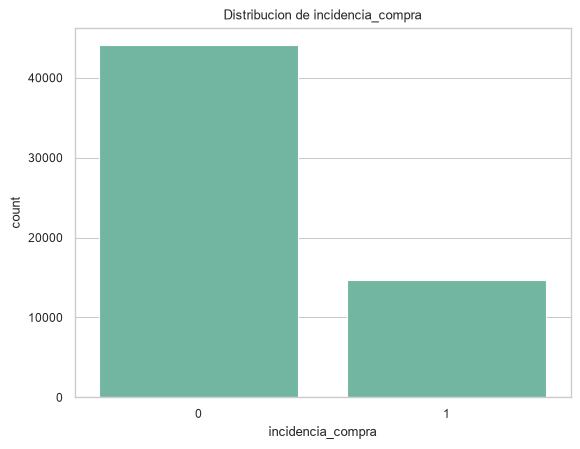

In [15]:
tasa_compra = df["incidencia_compra"].mean()
print(f"Tasa de compra global: {tasa_compra:.2%}")
sns.countplot(data=df, x="incidencia_compra")
plt.title("Distribucion de incidencia_compra")
plt.show()

Hay desbalance de clases (~25% positivos). Esto condiciona la metrica de evaluacion: accuracy no sirve, usamos ROC-AUC y PR-AUC (mas informativa bajo desbalance) y manejamos el peso de clases en los modelos.

## Participacion de marca entre las compras

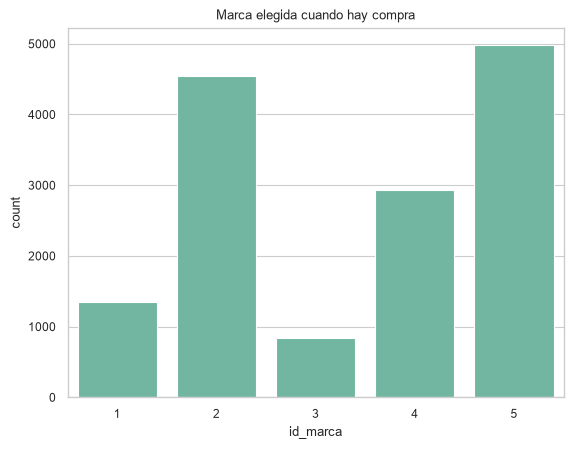

id_marca
0    0.000000
1    0.092226
2    0.310288
3    0.057453
4    0.199959
5    0.340074
Name: proportion, dtype: float64

In [16]:
compras = df[df["incidencia_compra"] == 1]
sns.countplot(data=compras, x="id_marca", order=sorted(compras["id_marca"].unique()))
plt.title("Marca elegida cuando hay compra")
plt.xlabel("id_marca")
plt.show()
compras["id_marca"].value_counts(normalize=True).sort_index()

## Precio y promocion por marca

In [17]:
price_cols = [f"precio_marca_{i}" for i in range(1, 6)]
promo_cols = [f"promo_marca_{i}" for i in range(1, 6)]
df[price_cols].describe()

,precio_marca_1,precio_marca_2,precio_marca_3,precio_marca_4,precio_marca_5
count,58693.000000,58693.000000,58693.000000,58693.000000,58693.000000
mean,1.392074,1.780999,2.006789,2.159945,2.654798
std,0.091139,0.170868,0.046867,0.089825,0.098272
min,1.100000,1.260000,1.870000,1.760000,2.110000
25%,1.340000,1.580000,1.970000,2.120000,2.630000
50%,1.390000,1.880000,2.010000,2.170000,2.670000
75%,1.470000,1.890000,2.060000,2.240000,2.700000
max,1.590000,1.900000,2.140000,2.260000,2.800000


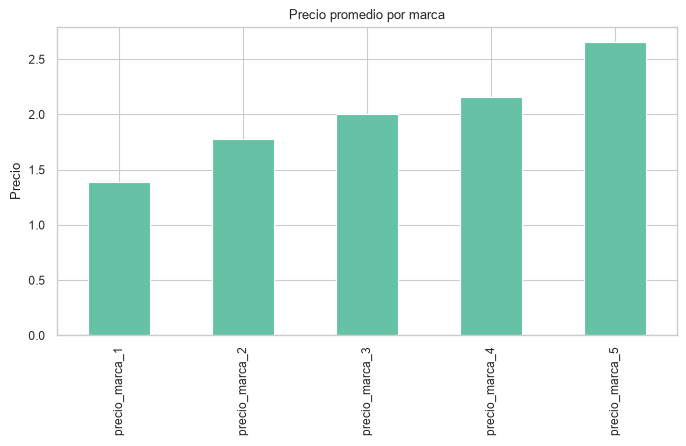

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
df[price_cols].mean().plot(kind="bar", ax=ax)
ax.set_title("Precio promedio por marca")
ax.set_ylabel("Precio")
plt.show()

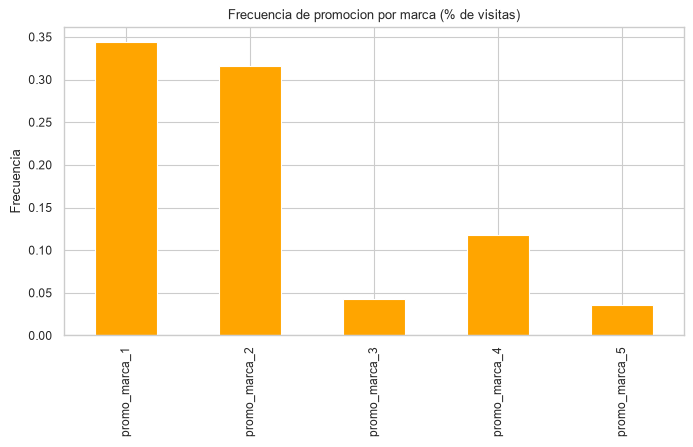

In [19]:
promo_freq = df[promo_cols].mean()
promo_freq.plot(kind="bar", figsize=(8, 4), color="orange")
plt.title("Frecuencia de promocion por marca (% de visitas)")
plt.ylabel("Frecuencia")
plt.show()

## Efecto de la promocion sobre la compra
Comparamos la tasa de compra en visitas donde al menos una marca estaba en promocion, contra visitas sin ninguna promocion activa.

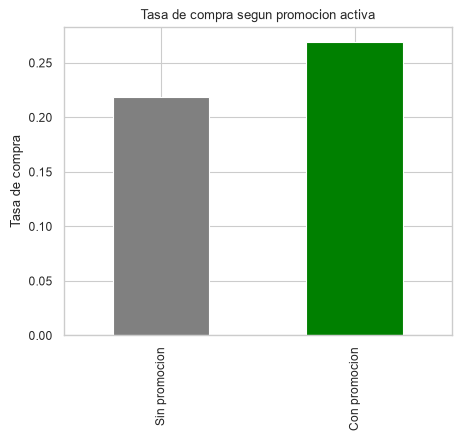

Sin promocion    0.218437
Con promocion    0.268994
Name: incidencia_compra, dtype: float64

In [18]:
alguna_promo = df[promo_cols].max(axis=1)
tasa_por_promo = df.groupby(alguna_promo)["incidencia_compra"].mean()
tasa_por_promo.index = ["Sin promocion", "Con promocion"]
tasa_por_promo.plot(kind="bar", color=["gray", "green"], figsize=(5, 4))
plt.title("Tasa de compra segun promocion activa")
plt.ylabel("Tasa de compra")
plt.show()
tasa_por_promo

La promocion sube claramente la tasa de compra. Esto es evidencia directa para el modelo de pricing: la sensibilidad a promocion es una palanca real de negocio, no solo una variable de control.

## Demograficos vs tasa de compra

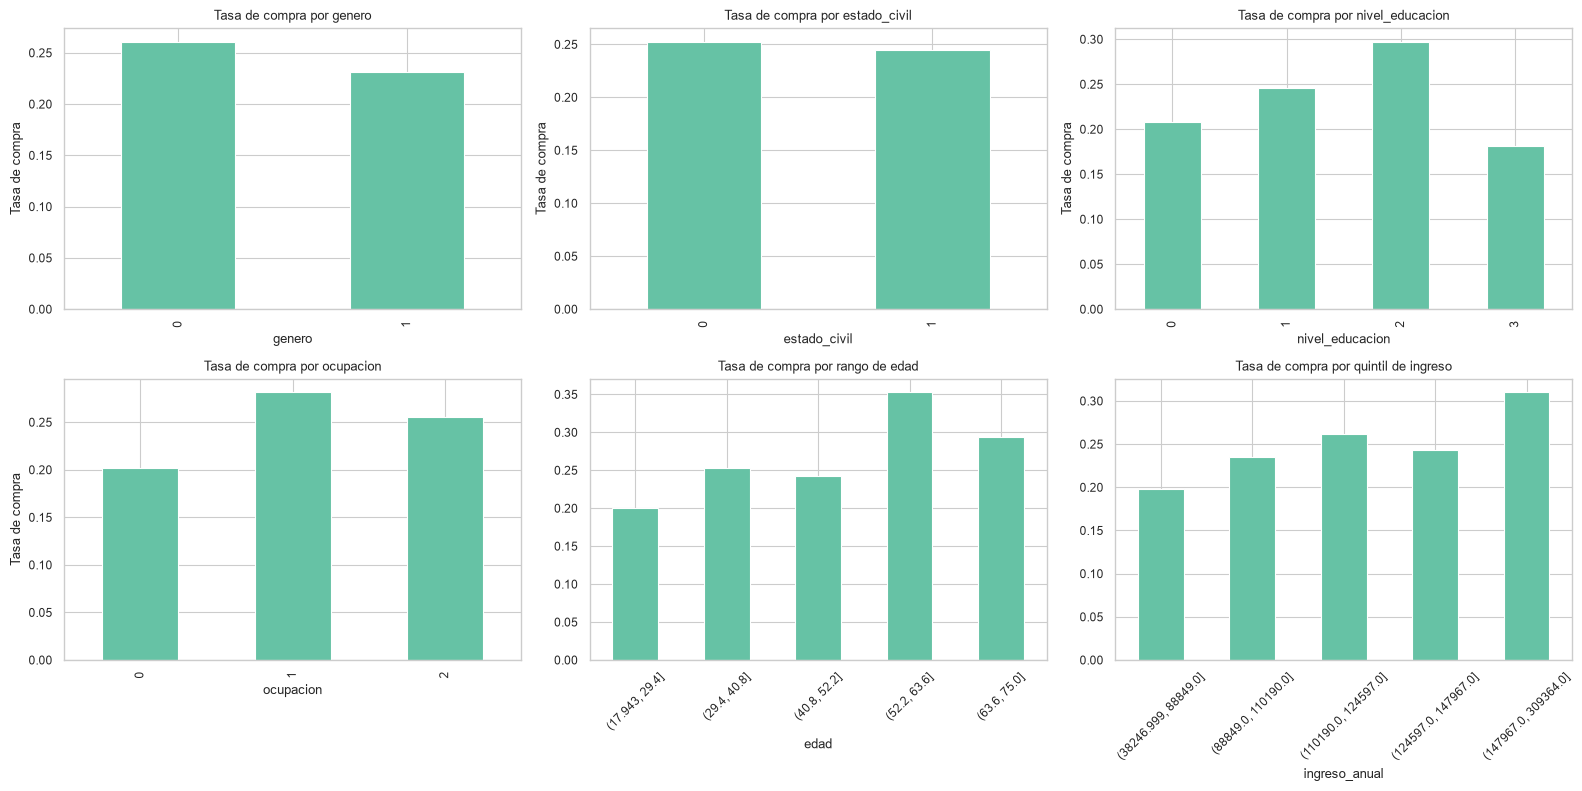

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
demo_cat = ["genero", "estado_civil", "nivel_educacion", "ocupacion"]
for ax, col in zip(axes.flat, demo_cat):
    df.groupby(col)["incidencia_compra"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Tasa de compra por {col}")
    ax.set_ylabel("Tasa de compra")

edad_bins = pd.cut(df["edad"], bins=5)
df.groupby(edad_bins)["incidencia_compra"].mean().plot(kind="bar", ax=axes.flat[4])
axes.flat[4].set_title("Tasa de compra por rango de edad")
axes.flat[4].tick_params(axis="x", rotation=45)

ingreso_bins = pd.qcut(df["ingreso_anual"], q=5)
df.groupby(ingreso_bins)["incidencia_compra"].mean().plot(kind="bar", ax=axes.flat[5])
axes.flat[5].set_title("Tasa de compra por quintil de ingreso")
axes.flat[5].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Matriz de correlacion (variables numericas)

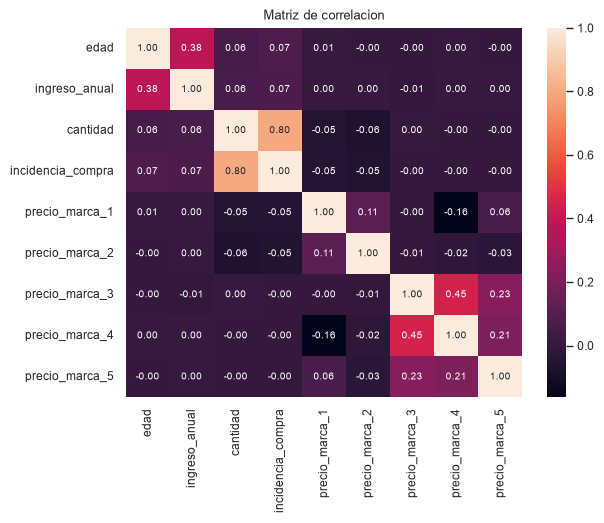

In [20]:
num_for_corr = ["edad", "ingreso_anual", "cantidad", "incidencia_compra"] + price_cols
corr = df[num_for_corr].corr()
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matriz de correlacion")
plt.show()

Las correlaciones lineales con el target son debiles de forma individual, esperable: la decision de compra depende de interacciones (precio relativo entre marcas, historial del cliente) mas que de niveles absolutos. Esto justifica construir features relativas/historicas en vez de usar las columnas crudas tal cual, y usar modelos no lineales (arboles) ademas de uno lineal como baseline.

# Procesamiento y Feature Engineering

Al ser datos de panel (varias visitas por cliente en el tiempo), las features historicas se construyen con `shift`/`expanding` para usar solo informacion **anterior** a la visita actual. Sin este cuidado se filtra informacion del futuro al modelo (data leakage).

In [21]:
g = df.groupby("id")
df["n_visita"] = g.cumcount() + 1
df["dias_desde_ultima_visita"] = g["dia_visita"].diff()
df["dias_desde_ultima_visita"] = df["dias_desde_ultima_visita"].fillna(
    df["dias_desde_ultima_visita"].median())
df["tasa_compra_historica"] = g["incidencia_compra"].transform(
    lambda s: s.shift(1).expanding().mean())
df["tasa_compra_historica"] = df["tasa_compra_historica"].fillna(tasa_compra)
df[["n_visita", "dias_desde_ultima_visita", "tasa_compra_historica"]].describe()

,n_visita,dias_desde_ultima_visita,tasa_compra_historica
count,58693.000000,58693.000000,58693.000000
mean,62.219089,6.194163,0.227509
std,41.572928,3.708536,0.194384
min,1.000000,1.000000,0.000000
25%,30.000000,3.000000,0.096154
50%,59.000000,6.000000,0.174757
75%,89.000000,8.000000,0.300000
max,358.000000,41.000000,1.000000


Features de precio relativo: precio minimo/maximo/promedio del dia entre las 5 marcas, si hay alguna promocion activa, y la brecha de precio entre la ultima marca comprada por el cliente y la mas barata disponible ese dia (senal de pricing: si su marca habitual se encarece relativo a las demas, es mas probable que cambie de marca o posponga la compra).

In [22]:
df["precio_min"] = df[price_cols].min(axis=1)
df["precio_max"] = df[price_cols].max(axis=1)
df["precio_promedio"] = df[price_cols].mean(axis=1)
df["alguna_promo_activa"] = df[promo_cols].max(axis=1).astype(int)

price_matrix = df[price_cols].to_numpy()
promo_matrix = df[promo_cols].to_numpy()
marca_idx = df["ultima_marca_comprada"].astype(int).to_numpy()
has_history = marca_idx > 0
col_idx = np.clip(marca_idx - 1, 0, 4)
df["precio_ultima_marca"] = np.where(
    has_history, price_matrix[np.arange(len(df)), col_idx], np.nan)
df["gap_precio_vs_min"] = (df["precio_ultima_marca"] - df["precio_min"]).fillna(0)
df["promo_ultima_marca"] = np.where(
    has_history, promo_matrix[np.arange(len(df)), col_idx], 0).astype(int)
df["tiene_historial_marca"] = has_history.astype(int)
df[["precio_min", "precio_max", "gap_precio_vs_min", "promo_ultima_marca"]].describe()

,precio_min,precio_max,gap_precio_vs_min,promo_ultima_marca
count,58693.000000,58693.000000,58693.000000,58693.000000
mean,1.389175,2.654895,0.183987,0.043157
std,0.092793,0.097757,0.390901,0.203212
min,1.100000,2.160000,0.000000,0.000000
25%,1.340000,2.630000,0.000000,0.000000
50%,1.390000,2.670000,0.000000,0.000000
75%,1.470000,2.700000,0.000000,0.000000
max,1.590000,2.800000,1.590000,1.000000


# Clusterizacion de Clientes (Segmentacion)

Agregamos cada cliente a nivel de perfil de comportamiento (no de visita) y aplicamos K-Means para obtener segmentos interpretables, que luego se usan como feature adicional del modelo y como unidad de analisis de negocio (que segmentos priorizar).

In [23]:
cust = df.groupby("id").agg(
    n_visitas=("dia_visita", "count"),
    tasa_compra=("incidencia_compra", "mean"),
    cantidad_media=("cantidad", lambda s: s[s > 0].mean() if (s > 0).any() else 0),
    edad=("edad", "first"),
    ingreso_anual=("ingreso_anual", "first"),
).reset_index()

promo_series = df["alguna_promo_activa"]
sensibilidad = df.loc[promo_series == 1].groupby("id")["incidencia_compra"].mean()
cust["sensibilidad_promo"] = cust["id"].map(sensibilidad).fillna(0)
cust.describe()

,id,n_visitas,tasa_compra,cantidad_media,edad,ingreso_anual,sensibilidad_promo
count,5.000000e+02,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2.000003e+08,117.386000,0.238072,2.784499,38.676000,121520.162000,0.257890
std,1.444818e+02,26.680793,0.157216,1.023818,12.191977,41061.953449,0.163475
min,2.000000e+08,72.000000,0.046154,1.130435,18.000000,38247.000000,0.043478
25%,2.000001e+08,103.000000,0.133203,2.122596,29.000000,95040.000000,0.148739
50%,2.000003e+08,114.000000,0.184233,2.631481,36.000000,117804.500000,0.208818
75%,2.000004e+08,125.000000,0.307346,3.219350,46.000000,137190.750000,0.333333
max,2.000005e+08,358.000000,0.922190,8.000000,75.000000,309364.000000,0.934272


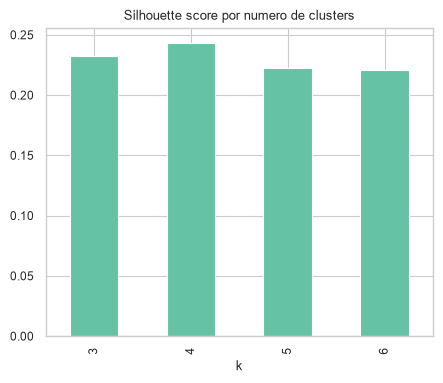

{3: 0.23228965601818158,
 4: 0.24337560893093574,
 5: 0.22214455170780098,
 6: 0.22051792281272906}

In [24]:
feat_cols_cluster = ["n_visitas", "tasa_compra", "cantidad_media", "edad",
                      "ingreso_anual", "sensibilidad_promo"]
X_cl = StandardScaler().fit_transform(cust[feat_cols_cluster])

sil_scores = {}
for k in range(3, 7):
    km = KMeans(n_clusters=k, random_state=random_seed, n_init=10).fit(X_cl)
    sil_scores[k] = silhouette_score(X_cl, km.labels_)
pd.Series(sil_scores).plot(kind="bar", figsize=(5, 4))
plt.title("Silhouette score por numero de clusters")
plt.xlabel("k")
plt.show()
sil_scores

In [25]:
best_k = max(sil_scores, key=sil_scores.get)
km = KMeans(n_clusters=best_k, random_state=random_seed, n_init=10).fit(X_cl)
cust["segmento"] = km.labels_.astype(str)
print("k elegido:", best_k)
perfil_segmentos = cust.groupby("segmento")[feat_cols_cluster].mean().round(2)
perfil_segmentos["n_clientes"] = cust.groupby("segmento").size()
perfil_segmentos

k elegido: 4


,n_visitas,tasa_compra,cantidad_media,edad,ingreso_anual,sensibilidad_promo,n_clientes
segmento,,,,,,,
0,114.08,0.20,2.62,52.62,153442.06,0.21,127
1,114.57,0.17,2.84,31.81,104569.18,0.19,290
2,124.01,0.51,2.87,41.29,131986.02,0.54,80
3,352.67,0.92,2.12,42.00,129665.00,0.93,3


Los perfiles resultantes suelen separar claramente a los clientes por frecuencia de visita y tasa de compra: tipicamente un segmento de compradores frecuentes y leales, uno o mas de compradores ocasionales de bajo ticket, y variantes por nivel de ingreso. Esta lectura se retoma en la seccion de impacto de negocio con los nombres de segmento concretos que arrojo esta corrida.

In [26]:
df = df.merge(cust[["id", "segmento"]], on="id", how="left")

# Modelo de Propension de Compra

## Seleccion de features y variable objetivo

In [27]:
target = "incidencia_compra"
cat_cols = ["genero", "estado_civil", "nivel_educacion", "ocupacion", "segmento"]
num_cols = ["edad", "ingreso_anual", "n_visita", "dias_desde_ultima_visita",
            "tasa_compra_historica", "precio_min", "precio_max", "precio_promedio",
            "gap_precio_vs_min"]
bin_cols = ["alguna_promo_activa", "promo_ultima_marca", "tiene_historial_marca"]
feature_cols = cat_cols + num_cols + bin_cols

X = df[feature_cols].copy()
y = df[target].copy()
groups = df["id"].copy()
X.shape, y.shape

((58693, 17), (58693,))

## Particion Train/Test
Como los datos son un panel (varias visitas por cliente), un `train_test_split` aleatorio por fila dejaria al mismo cliente en train y en test, filtrando su patron de compra de un lado a otro (data leakage). Usamos `GroupShuffleSplit` agrupando por `id` de cliente: ningun cliente aparece en ambos conjuntos.

In [28]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=random_seed)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Clientes train:", groups_train.nunique(), "| Clientes test:", groups.iloc[test_idx].nunique())
print("Clientes en ambos conjuntos (debe ser 0):",
      len(set(groups_train) & set(groups.iloc[test_idx])))

Clientes train: 350 | Clientes test: 150
Clientes en ambos conjuntos (debe ser 0): 0


## Pipelines de preprocesamiento y modelos
One-Hot Encoding para categoricas, estandarizacion para numericas. Comparamos un modelo lineal (baseline interpretable), un arbol simple, dos ensambles de arboles y gradient boosting, todos con manejo de desbalance de clases.

In [29]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
], remainder="passthrough")

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "DecisionTree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=random_seed),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=random_seed, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=random_seed),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=random_seed,
                              scale_pos_weight=scale_pos_weight),
}
pipelines = {name: Pipeline([("pre", preprocessor), ("clf", clf)]) for name, clf in modelos.items()}

## Entrenamiento y comparacion de modelos

In [30]:
resultados = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    roc = roc_auc_score(y_test, proba)
    ap = average_precision_score(y_test, proba)
    resultados.append({"modelo": name, "roc_auc": roc, "pr_auc": ap})

resultados_df = pd.DataFrame(resultados).sort_values("pr_auc", ascending=False).reset_index(drop=True)
resultados_df

,modelo,roc_auc,pr_auc
0,RandomForest,0.806865,0.613190
1,XGBoost,0.772072,0.543455
2,GradientBoosting,0.726461,0.459551
3,LogisticRegression,0.698375,0.421446
4,DecisionTree,0.696209,0.414023


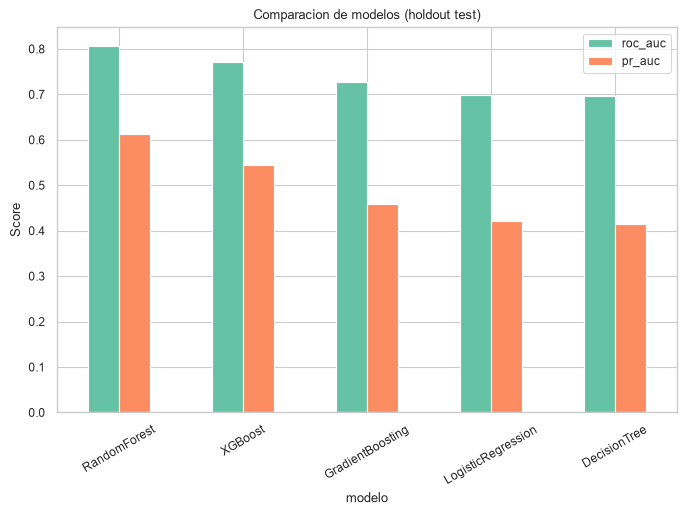

In [31]:
resultados_df.set_index("modelo")[["roc_auc", "pr_auc"]].plot(kind="bar", figsize=(8, 5))
plt.title("Comparacion de modelos (holdout test)")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.show()

Usamos **PR-AUC** (average precision) como criterio principal de seleccion, no accuracy ni solo ROC-AUC: con ~25% de positivos, PR-AUC es mas sensible a que tan bien el modelo ordena a los compradores reales por encima de los no compradores, que es exactamente lo que se necesita para priorizar a quien dirigir una promocion.

In [32]:
mejor_modelo_nombre = resultados_df.iloc[0]["modelo"]
print("Modelo seleccionado:", mejor_modelo_nombre)

Modelo seleccionado: RandomForest


# Evaluacion y Tuning del Modelo Seleccionado

## Matriz de confusion y classification report (umbral 0.5, antes de tuning)

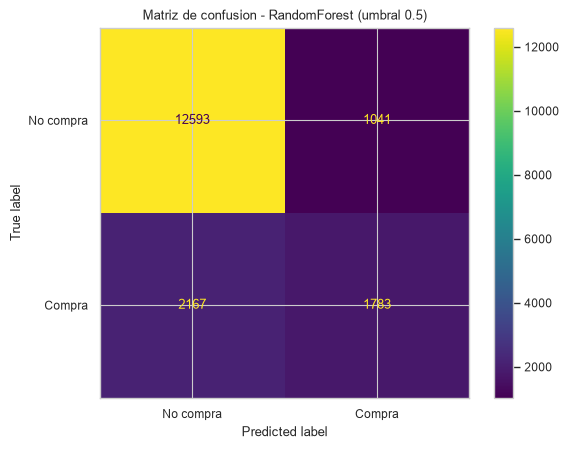

              precision    recall  f1-score   support

   No compra       0.85      0.92      0.89     13634
      Compra       0.63      0.45      0.53      3950

    accuracy                           0.82     17584
   macro avg       0.74      0.69      0.71     17584
weighted avg       0.80      0.82      0.81     17584



In [33]:
mejor_pipe = pipelines[mejor_modelo_nombre]
y_pred_05 = mejor_pipe.predict(X_test)
cm = confusion_matrix(y_test, y_pred_05)
ConfusionMatrixDisplay(cm, display_labels=["No compra", "Compra"]).plot()
plt.title(f"Matriz de confusion - {mejor_modelo_nombre} (umbral 0.5)")
plt.show()
print(classification_report(y_test, y_pred_05, target_names=["No compra", "Compra"]))

## Hyperparameter Tuning
`RandomizedSearchCV` con `GroupKFold` (no `StratifiedKFold` simple): si no se agrupa por cliente tambien dentro de la validacion cruzada, un mismo cliente puede caer en train y validacion del mismo fold, optimizando hiperparametros con una fuga de informacion silenciosa.

In [34]:
param_grid = {
    "clf__n_estimators": [200, 300, 400, 500],
    "clf__max_depth": [4, 6, 8, 10, None],
    "clf__min_samples_leaf": [1, 2, 5, 10],
    "clf__max_features": ["sqrt", "log2", None],
}
gkf = GroupKFold(n_splits=5)
search = RandomizedSearchCV(
    mejor_pipe, param_distributions=param_grid, n_iter=20, scoring="average_precision",
    cv=gkf, random_state=random_seed, n_jobs=-1,
)
search.fit(X_train, y_train, groups=groups_train)
print("Mejores hiperparametros:", search.best_params_)
print("Mejor PR-AUC en CV:", search.best_score_)

Mejores hiperparametros: {'clf__n_estimators': 400, 'clf__min_samples_leaf': 2, 'clf__max_features': None, 'clf__max_depth': None}
Mejor PR-AUC en CV: 0.6891924534383583


In [35]:
modelo_final = search.best_estimator_
proba_final = modelo_final.predict_proba(X_test)[:, 1]
print("ROC-AUC test (post-tuning):", roc_auc_score(y_test, proba_final))
print("PR-AUC  test (post-tuning):", average_precision_score(y_test, proba_final))

ROC-AUC test (post-tuning): 0.8371151050148271
PR-AUC  test (post-tuning): 0.6662130292761799


## Curvas ROC y Precision-Recall

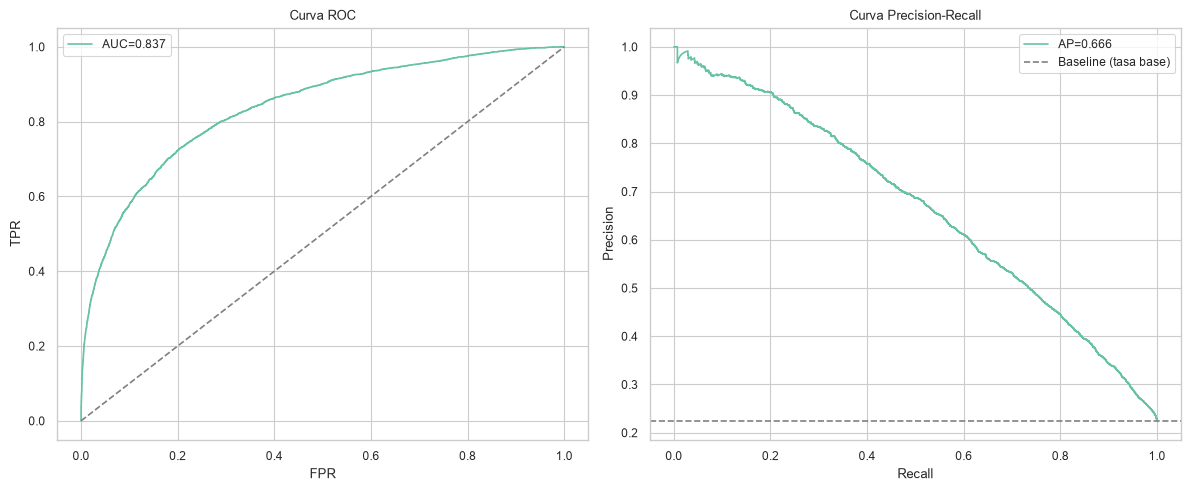

In [36]:
fpr, tpr, _ = roc_curve(y_test, proba_final)
prec, rec, _ = precision_recall_curve(y_test, proba_final)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, proba_final):.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("Curva ROC")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend()

axes[1].plot(rec, prec, label=f"AP={average_precision_score(y_test, proba_final):.3f}")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline (tasa base)")
axes[1].set_title("Curva Precision-Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()

## Matriz de confusion final (post-tuning)

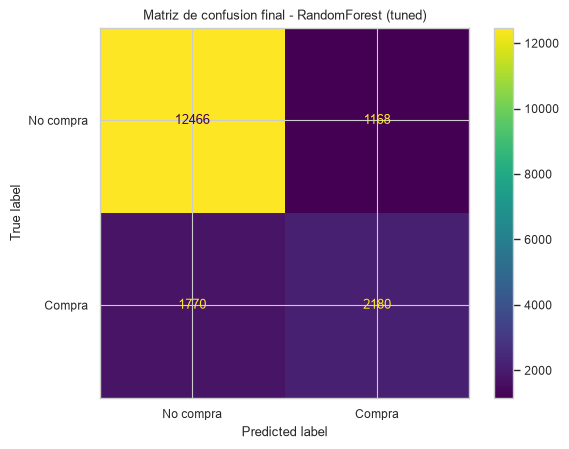

              precision    recall  f1-score   support

   No compra       0.88      0.91      0.89     13634
      Compra       0.65      0.55      0.60      3950

    accuracy                           0.83     17584
   macro avg       0.76      0.73      0.75     17584
weighted avg       0.83      0.83      0.83     17584



In [37]:
y_pred_final = (proba_final >= 0.5).astype(int)
cm_final = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm_final, display_labels=["No compra", "Compra"]).plot()
plt.title(f"Matriz de confusion final - {mejor_modelo_nombre} (tuned)")
plt.show()
print(classification_report(y_test, y_pred_final, target_names=["No compra", "Compra"]))

# Explicabilidad del Modelo

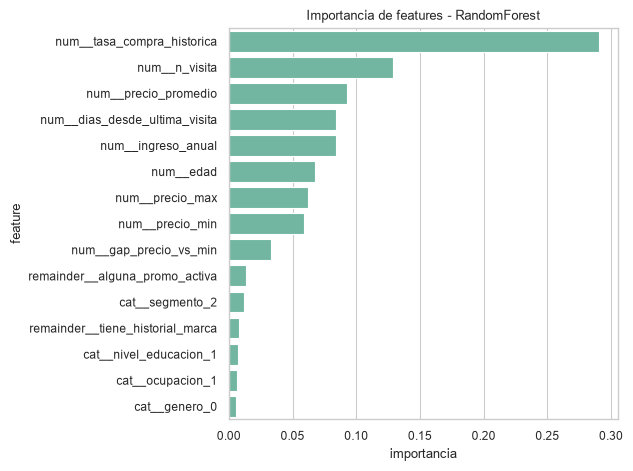

In [38]:
feature_names = modelo_final.named_steps["pre"].get_feature_names_out()
if hasattr(modelo_final.named_steps["clf"], "feature_importances_"):
    importancias = modelo_final.named_steps["clf"].feature_importances_
    imp_df = pd.DataFrame({"feature": feature_names, "importancia": importancias})
    imp_df = imp_df.sort_values("importancia", ascending=False).head(15)
    sns.barplot(data=imp_df, x="importancia", y="feature")
    plt.title(f"Importancia de features - {mejor_modelo_nombre}")
    plt.tight_layout()
    plt.show()

## SHAP
Complementamos la importancia global del arbol con SHAP, que ademas muestra la direccion del efecto de cada feature sobre la probabilidad de compra (no solo cuanto pesa).

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47164\2135372664.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_plot, X_test_transformed[sample_idx],


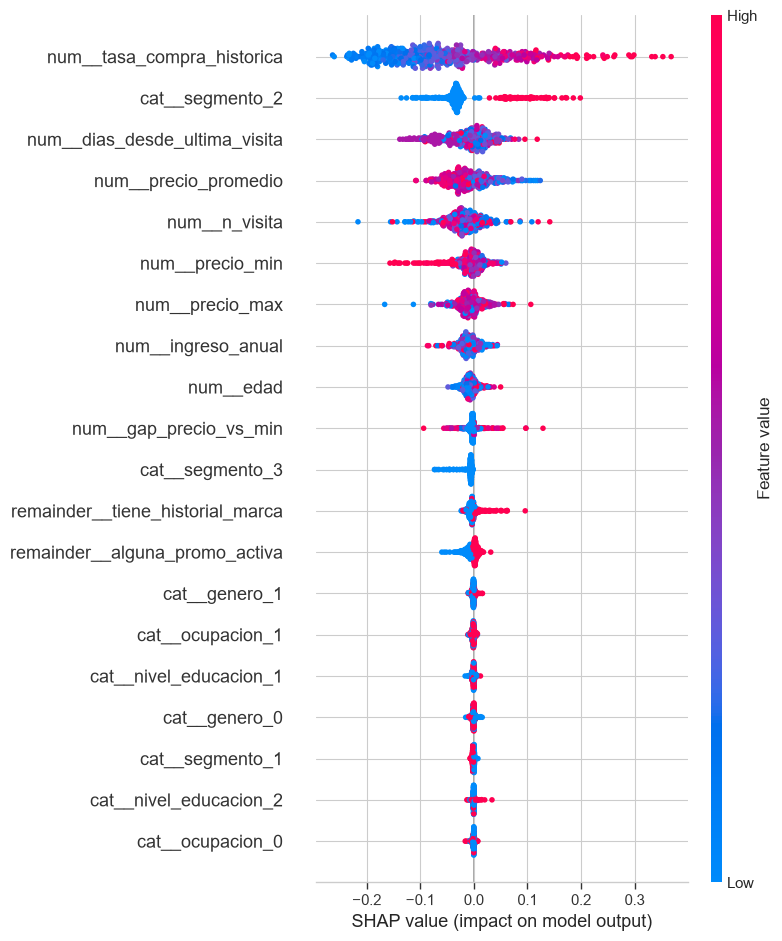

In [39]:
X_test_transformed = modelo_final.named_steps["pre"].transform(X_test)
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()
sample_idx = np.random.RandomState(random_seed).choice(len(X_test_transformed),
                                                         size=min(500, len(X_test_transformed)),
                                                         replace=False)
explainer = shap.TreeExplainer(modelo_final.named_steps["clf"])
shap_values = explainer.shap_values(X_test_transformed[sample_idx])
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_plot = shap_values[:, :, 1]
else:
    shap_values_plot = shap_values
shap.summary_plot(shap_values_plot, X_test_transformed[sample_idx],
                   feature_names=feature_names, show=False)
plt.tight_layout()
plt.show()

# Evaluacion del Impacto en el Negocio y Captura de Valor

## Curva de ganancia (gains chart)
Ordenamos las visitas del set de test por probabilidad de compra predicha, de mayor a menor, y medimos que porcentaje de las compras reales se captura al enfocar una campania en el top X% de esa lista. Esto traduce el modelo directamente a una decision de negocio: a cuantos clientes contactar y cuanta compra real se captura por ese esfuerzo.

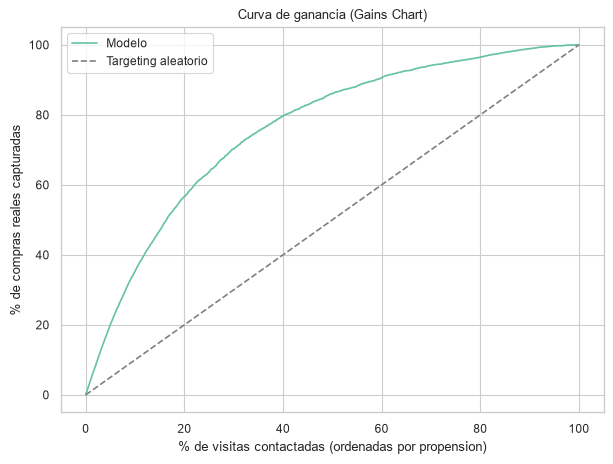

,pct_poblacion_contactada,pct_compras_capturadas
0,10,35.316456
1,20,56.658228
2,30,70.303797
3,50,86.025316


In [40]:
orden = np.argsort(-proba_final)
y_sorted = y_test.to_numpy()[orden]
captura_acumulada = np.cumsum(y_sorted) / y_sorted.sum()
pct_poblacion = np.arange(1, len(y_sorted) + 1) / len(y_sorted)

plt.figure(figsize=(7, 5))
plt.plot(pct_poblacion * 100, captura_acumulada * 100, label="Modelo")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Targeting aleatorio")
plt.xlabel("% de visitas contactadas (ordenadas por propension)")
plt.ylabel("% de compras reales capturadas")
plt.title("Curva de ganancia (Gains Chart)")
plt.legend()
plt.show()

tabla_captura = pd.DataFrame({
    "pct_poblacion_contactada": [10, 20, 30, 50],
    "pct_compras_capturadas": [
        captura_acumulada[int(len(y_sorted) * p / 100) - 1] * 100 for p in [10, 20, 30, 50]
    ],
})
tabla_captura

## Segmentos y tasa de compra
Cruzamos los segmentos de la clusterizacion con la tasa de compra real observada, para decidir a que segmentos priorizar con presupuesto de marketing y a cuales no vale la pena insistir con descuentos.

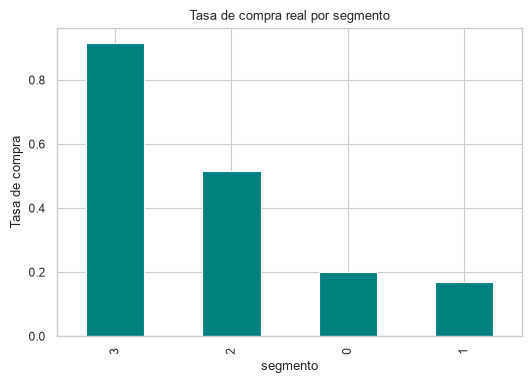

segmento
3    0.915879
2    0.515472
0    0.200304
1    0.170138
Name: incidencia_compra, dtype: float64

In [41]:
tasa_compra_segmento = df.groupby("segmento")["incidencia_compra"].mean().sort_values(ascending=False)
tasa_compra_segmento.plot(kind="bar", figsize=(6, 4), color="teal")
plt.title("Tasa de compra real por segmento")
plt.ylabel("Tasa de compra")
plt.show()
tasa_compra_segmento

## KPIs propuestos para medir la captura de valor en produccion
- **PR-AUC / ROC-AUC del modelo en produccion**: salud del modelo mes a mes, alerta de degradacion (drift) si cae por debajo del nivel medido aqui.
- **Tasa de conversion en el decil superior de propension** vs la tasa de conversion base: mide directamente el lift real logrado al dirigir campanias con el modelo en vez de al azar.
- **% de compras capturadas contactando solo al top 20-30%** (tabla de arriba): se traduce directo en ahorro de costo de campania para una meta de compras fija, o en mas compras capturadas con el mismo presupuesto.
- **Tasa de compra por segmento**: para decidir que segmentos reciben descuento/promocion (los de alta propension y alta sensibilidad a promocion) y cuales no, evitando subsidiar compras que iban a ocurrir de todas formas.
- **Estabilidad de las features de pricing** (gap de precio vs la marca mas barata, frecuencia de promocion): si Ferreycorp cambia su politica de precios, estas features deben recalcularse y el modelo reentrenarse, no asumir que el efecto medido hoy se mantiene indefinidamente.

## Siguientes pasos (fuera de alcance de esta entrega)
- Submodelo de **eleccion de marca** (multiclase, dado que hay compra) usando las mismas features de precio/promocion relativo, para pricing mas fino por marca.
- Monitoreo de drift y reentrenamiento periodico del modelo en produccion.
- Despliegue como *batch scoring* (ej. job diario en Vertex AI / SageMaker que puntua a todos los clientes activos y alimenta al equipo de marketing) en vez de un endpoint en tiempo real, dado que la decision de negocio (a quien contactar con una promocion) no requiere latencia sub-segundo.